# 02 - Connectivity, diameter and radius (Panama Papers)

**Goal:** describe connectivity and distances: components, diameter and radius, in hops (unweighted).

Steps:
1. Load the graphs built in notebook 01
2. Components (bipartite and projection)
3. Exact diameter and radius per component on the projection
4. Eccentricity distribution of the largest projection component
5. Bounds for the bipartite giant component
6. Conclusions

**Method.** Diameter = max eccentricity, radius = min eccentricity, eccentricity of a node = its largest shortest-path distance. Distances are in hops. Both are defined per connected component, since the graphs are disconnected.
- Projection: exact, BFS from every node (scipy `csgraph`, chunked). 109 s for the largest component (26,643 nodes).
- Bipartite giant component (310,904 nodes): all-pairs is too heavy, so we give a lower bound on the diameter (20 double sweeps) and an upper bound on the radius (eccentricity of the midpoint of the longest path found).

In [1]:
import sys, pickle, json
sys.path.insert(0, "..")
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from src.load import PROC
from src.diameter import csr, exact
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = "../figures/"
B, P = pickle.load(open(PROC / "graphs.pkl", "rb"))
res = json.load(open(PROC / "diameter.json"))  # written by src/diameter.py

## 2. Components

In [2]:
rows = []
for name, G in [("bipartite", B), ("projection", P)]:
    s = sorted((len(c) for c in nx.connected_components(G)), reverse=True)
    rows.append({"graph": name, "nodes": G.number_of_nodes(), "components": len(s), "largest": s[0],
                 "largest_share_%": round(100 * s[0] / G.number_of_nodes(), 1), "2nd": s[1], "3rd": s[2],
                 "isolated": sum(1 for x in s if x == 1)})
pd.DataFrame(rows).set_index("graph")

,nodes,components,largest,largest_share_%,2nd,3rd,isolated
graph,,,,,,,
bipartite,468623,12218,310904,66.3,3642,2995,0
projection,213634,139643,26643,12.5,132,126,129607


## 3. Exact diameter and radius per component (projection, 5 largest)

In [3]:
t = pd.DataFrame(res["projection_exact"]); t.index = [f"#{i+1}" for i in range(len(t))]; t

,size,diameter,radius,n_center_nodes,seconds
#1,26643,30,16,74,109.2
#2,132,6,3,10,0.0
#3,126,7,4,24,0.0
#4,121,5,3,31,0.0
#5,115,9,5,3,0.0


## 4. Eccentricity distribution, largest projection component

size 26643 diameter 30 radius 16 center nodes 74


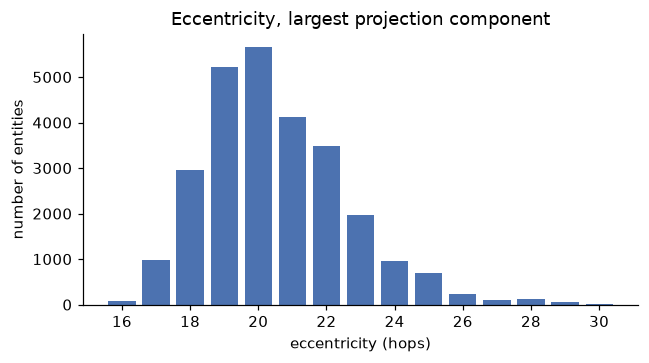

In [4]:
big = list(max(nx.connected_components(P), key=len)); A = csr(P, big)
ecc = exact(A)
print("size", len(big), "diameter", int(ecc.max()), "radius", int(ecc.min()), "center nodes", int((ecc == ecc.min()).sum()))
plt.figure(figsize=(6, 3.4)); v, c = np.unique(ecc, return_counts=True)
plt.bar(v, c, color="#4C72B0"); plt.xlabel("eccentricity (hops)"); plt.ylabel("number of entities")
plt.title("Eccentricity, largest projection component"); plt.tight_layout(); plt.savefig(FIG + "02_eccentricity.png"); plt.show()

## 5. Bipartite giant component (bounds)

In [5]:
print(json.dumps(res["bipartite_bounds"], indent=1))

{
 "size": 310904,
 "diameter_lower_bound": 37,
 "radius_upper_bound": 20,
 "sweeps": 20,
 "seconds": 2.2
}


## 6. Conclusions

- The projection's giant component (26,643 entities, 12.5 % of entities) has diameter 30 and radius 16. The next four components are tiny (115 to 132 entities, diameter 5 to 9).
- The bipartite giant component (310,904 nodes, 66 %) has a diameter of at least 37 and a radius of at most 20 (bounds, 20 sweeps). Distances in a bipartite graph count entity-connector steps, so a path of length 2 equals 1 hop in the projection.
- Diameter 30 against radius 16 suggests long paths at the periphery around a more compact core. To check with the eccentricity histogram before writing it in the report.
- **To state in the report:** distances are unweighted, computed per component, exact on the projection and bounded on the bipartite graph. The hub cap affects the distances (removing hubs lengthens paths).